In [83]:
# Implementing Figure Two Experiment from the Gatmiry paper (based on the simple experiment file)


import torch
from matplotlib import pyplot as plt
import sys
import time
import os
import numpy as np


#####################################################
# In this notebook, we train a 3-layer linear transformer with
# - context-length 20
# - covariate dimension 5, standard Gaussian distribution
# We plot
# - test loss against number of iterations
# - imshow of each parameter matrix at end of training
# - distance-to-identity of each parameter matrix
#####################################################

#use cuda if available, else use cpu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#torch.cuda.set_device(1)
# import the model and some useful functions
from linear_transformer import Transformer_F, attention, generate_data, in_context_loss

# set up some print options
np.set_printoptions(precision = 2, suppress = True)
torch.set_printoptions(precision=2)

#begin logging
log_dir = 'log' 
#exp_dir = 'simple_demonstration' 
cur_dir = log_dir #os.path.join(log_dir, exp_dir)
os.makedirs(cur_dir, exist_ok=True)
#f = open(cur_dir + '/train.log', "a", 1)
#sys.stdout = f

print(f"Running on device: {device}.")

Running on device: cuda.


In [84]:
# Set up problem parameters

lr = 0.001
clip_r = 1000
alg = 'adam'
mode = 'normal'

N = 10     # context length (no assumption given in paper)
d = 5        # dimension

n_head = 1  # 1-headed attention
B = 4000  # 4000 minibatch size
var = 0.05  # initializations scale of transformer parameter
shape_k = 0.1  # shape_k: parameter for Gamma distributed covariates
max_iters = 10000  # Number of Iterations to run
hist_stride = 1  # stride for saved model paramters in `train.ipynb'
stride = 100

# a convenience function for taking a step and clipping
def clip_and_step(allparam, optimizer, clip_r = None):
    norm_p=None
    grad_all = allparam.grad
    if clip_r is not None:
        norm_p = grad_all.norm().item()

        if norm_p > clip_r:
            grad_all.mul_(clip_r/norm_p)
    optimizer.step()
    return norm_p

In [89]:
import numpy as np

filename_format = '/linearTF_exp_{}_{}.pth'
# File name for individual model
filename = filename_format.format(N, d)
filename = (cur_dir + filename)
hist_dict = {}


seeds = [0, 1, 2] # Multiple seeds in case one of the simulations produces an odd result, we can average it's results out
n_layers_loops = [1, 2, 5, 10] # corresponds to the number of layers/loops in a transformer model

keys = [(s, n) for s in seeds for n in n_layers_loops]
for i, key in enumerate(keys):
    print(f"Running seed: {i + 1}/{len(keys)} with key: {key}.")
    sd = key[0]
    n_layer = key[1]
    prob_seed = sd
    opt_seed = sd
        
    hist_dict[key] = []
    
    #set seed and initialize model
    torch.manual_seed(opt_seed)
    model = Transformer_F(key[1], n_head, d, var)
    model.to(device)
    #initialize algorithm. Important: set beta = 0.9 for adam, 0.999 is very slow
    if alg == 'sgd':
        optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=0)
    elif alg == 'adam':
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.9), weight_decay=0)
    else: assert False
    
    #set seed and initialize initial training batch
    np.random.seed(prob_seed)
    torch.manual_seed(prob_seed)
    
    for t in range(max_iters):
        start = time.time()
        # save model parameters
        if t%hist_stride ==0:
            hist_dict[key].append(model.allparam.clone().detach())
        #  generate a new batch of training set
        Z, y = generate_data(mode,N,d,B,shape_k)
        Z = Z.to(device)
        y = y.to(device)
        loss = in_context_loss(model, Z, y).to(device)


        
        # compute gradient, take step
        loss.backward()
        grad_norm = clip_and_step(model.allparam, optimizer, clip_r=clip_r)

        # Do not continue if the norm gets too large
        if np.isnan(grad_norm):
            print("Existing early, grad_norm is NaN.")
            break

        optimizer.zero_grad()
        end=time.time()
        if t % 100 ==0 or t < 5:
            print('iter {} | Loss: {}  time: {}  gradnorm: {}'.format(t,loss.item(), end-start, grad_norm))
    
    print(f"Finished running seed: {i + 1}/{len(keys)} with key: {key}.")

# Saving results to the weight file
torch.save({'hist_dict':hist_dict}, filename)

Running seed: 1/12 with key: (0, 1).
iter 0 | Loss: 5.583387851715088  time: 0.006272554397583008  gradnorm: 4.943443298339844
iter 1 | Loss: 5.09586238861084  time: 0.005284547805786133  gradnorm: 4.565327167510986
iter 2 | Loss: 5.328909873962402  time: 0.005575895309448242  gradnorm: 4.799430847167969
iter 3 | Loss: 5.160664081573486  time: 0.0053136348724365234  gradnorm: 4.6755194664001465
iter 4 | Loss: 5.127560138702393  time: 0.005103111267089844  gradnorm: 4.502877712249756
iter 100 | Loss: 4.155155658721924  time: 0.0026051998138427734  gradnorm: 3.831400156021118
iter 200 | Loss: 3.590285062789917  time: 0.0030329227447509766  gradnorm: 3.3312251567840576
iter 300 | Loss: 2.9695944786071777  time: 0.0035872459411621094  gradnorm: 2.7237231731414795
iter 400 | Loss: 2.45053768157959  time: 0.0025963783264160156  gradnorm: 1.9503016471862793
iter 500 | Loss: 2.0841314792633057  time: 0.0026254653930664062  gradnorm: 1.3367317914962769
iter 600 | Loss: 1.9352136850357056  time:

In [92]:
####################################
# compute test loss for available checkpoints
####################################

TEST_SEED = 99

hist_dict = torch.load(filename)['hist_dict']
loss_dict = {}
for key, history in hist_dict.items():
    # NaN marks iterations that were not reached (e.g. if training stopped early).
    test_losses = torch.full((len(range(0, max_iters, stride)),), float('nan'))

    np.random.seed(TEST_SEED)
    torch.manual_seed(TEST_SEED)
    Z, y = generate_data(mode, N, d, B, shape_k)
    Z = Z.to(device)
    y = y.to(device)
    model = Transformer_F(key[1], n_head, d, var).to(device)

    for iteration in range(0, max_iters, stride):
        if iteration % hist_stride != 0:
            continue
        history_index = iteration // hist_stride
        if history_index >= len(history):
            break

        snapshot = history[history_index]
        if not torch.isfinite(snapshot).all():
            continue

        with torch.no_grad():
            model.allparam.copy_(snapshot)
            test_losses[iteration // stride] = in_context_loss(model, Z, y).item()

    loss_dict[key] = test_losses

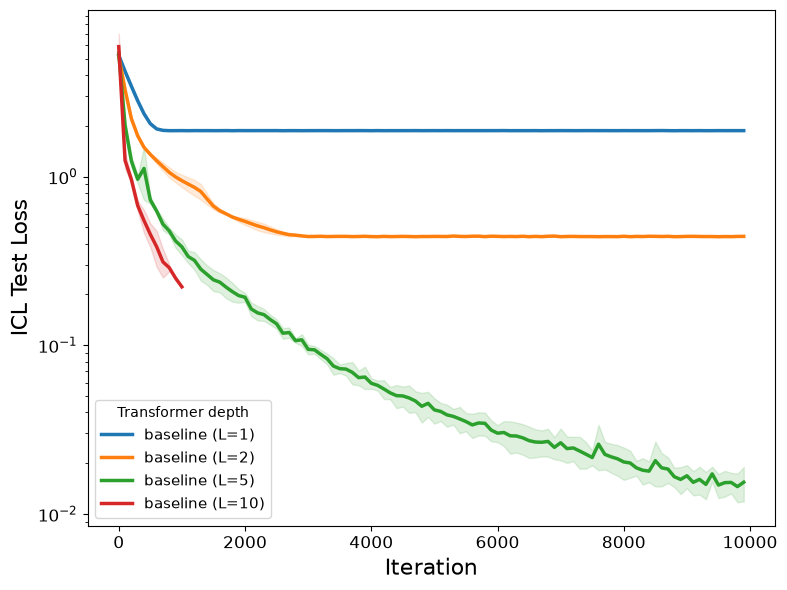

In [93]:
####################################
# plot mean test loss by layer/loop configuration
####################################

fig_dir = 'figures'
os.makedirs(fig_dir, exist_ok=True)

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
iterations = np.arange(0, max_iters, stride)
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

all_keys = list(loss_dict)
all_losses = torch.stack([loss_dict[key] for key in all_keys])
for color, layer_count in zip(colors, n_layers_loops):
    run_indices = [i for i, key in enumerate(all_keys) if key[1] == layer_count]
    if not run_indices:
        continue

    layer_losses = all_losses[run_indices]
    valid = torch.isfinite(layer_losses)
    count = valid.sum(dim=0)
    values = torch.where(valid, layer_losses, torch.zeros_like(layer_losses))
    mean_loss = values.sum(dim=0) / count.clamp_min(1)
    mean_loss[count == 0] = float('nan')

    ax.plot(iterations, mean_loss.cpu().numpy(), color=color, lw=2.5,
            label=f'baseline (L={layer_count})')

    variance = torch.where(
        valid,
        (layer_losses - mean_loss.unsqueeze(0)) ** 2,
        torch.zeros_like(layer_losses),
    ).sum(dim=0) / count.clamp_min(1)
    std_loss = variance.sqrt()
    has_multiple_runs = count > 1
    lower = torch.where(has_multiple_runs, mean_loss - std_loss, torch.nan)
    upper = torch.where(has_multiple_runs, mean_loss + std_loss, torch.nan)
    ax.fill_between(
        iterations,
        lower.cpu().numpy(),
        upper.cpu().numpy(),
        color=color,
        alpha=0.15,
    )

ax.set_xlabel('Iteration', fontsize=16)
ax.set_ylabel('ICL Test Loss', fontsize=16)
ax.tick_params(axis='both', which='major', labelsize=12)
ax.set_yscale('log')
ax.legend(title='Transformer depth', fontsize=11)
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'figure_two_test_loss_by_layers.pdf'), dpi=600)
plt.show()

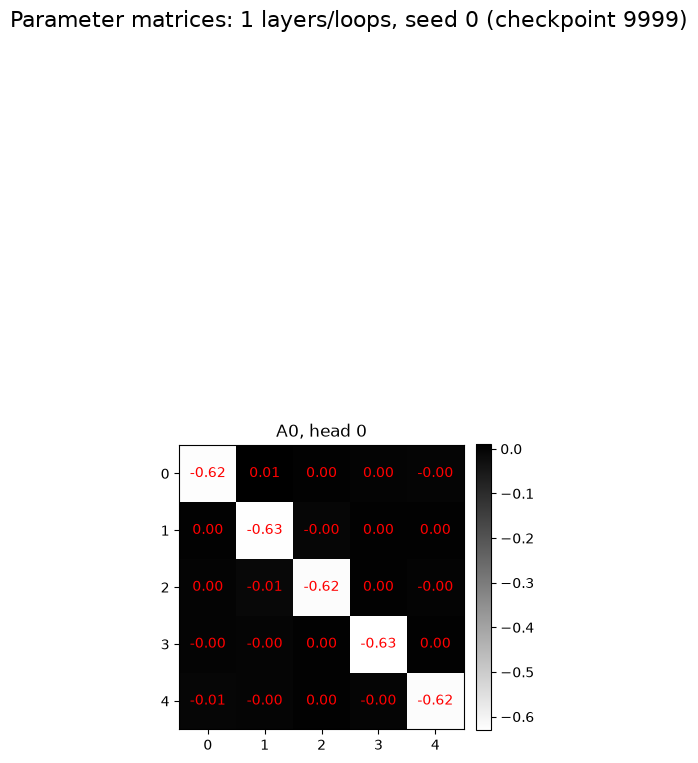

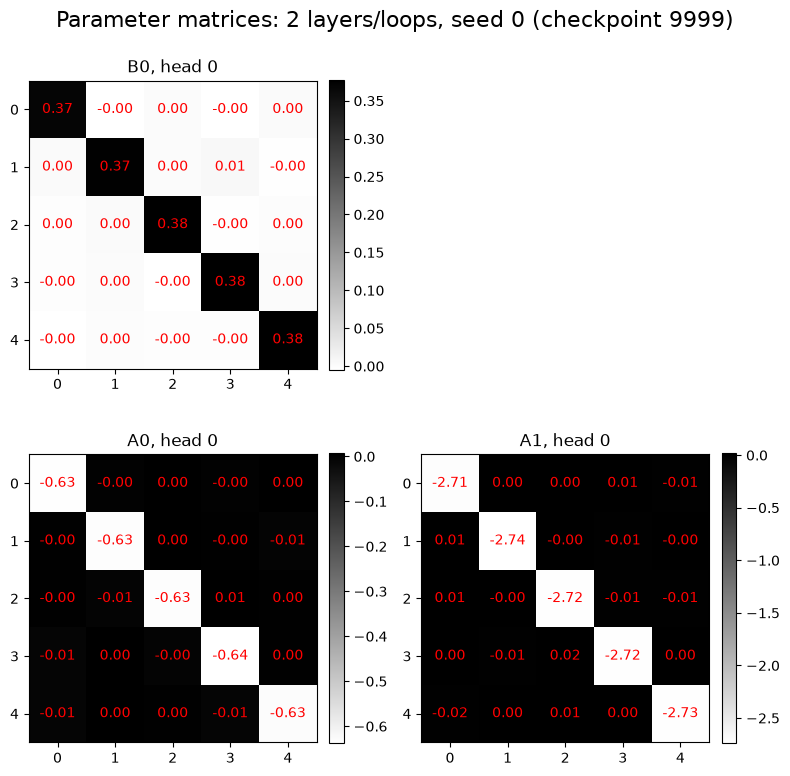

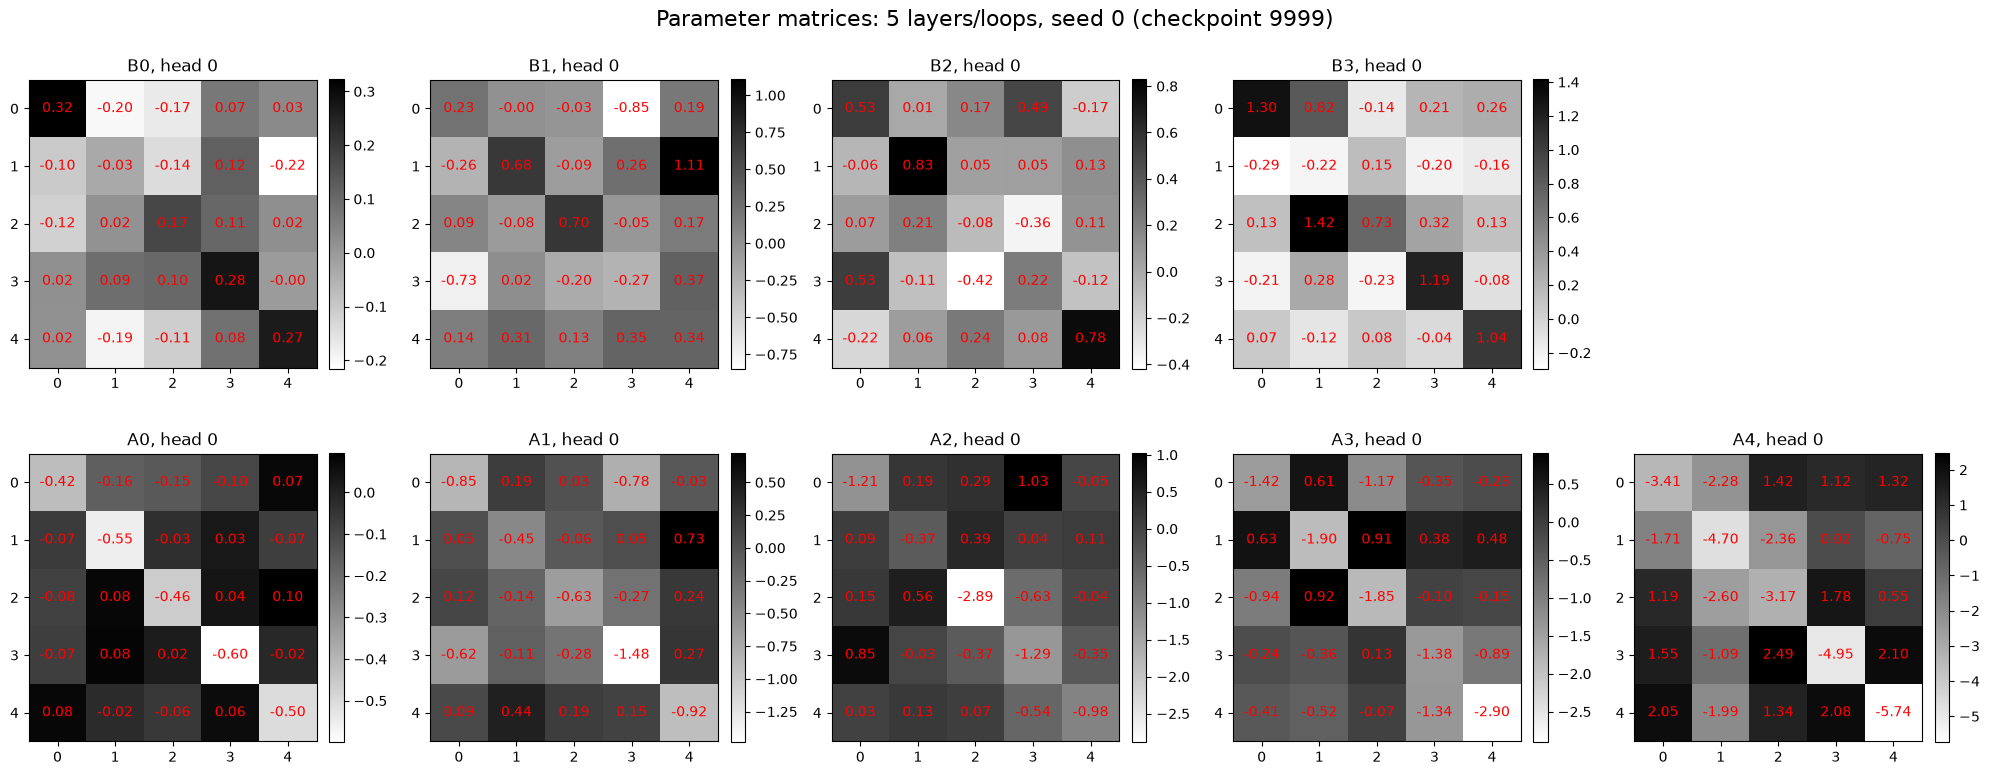

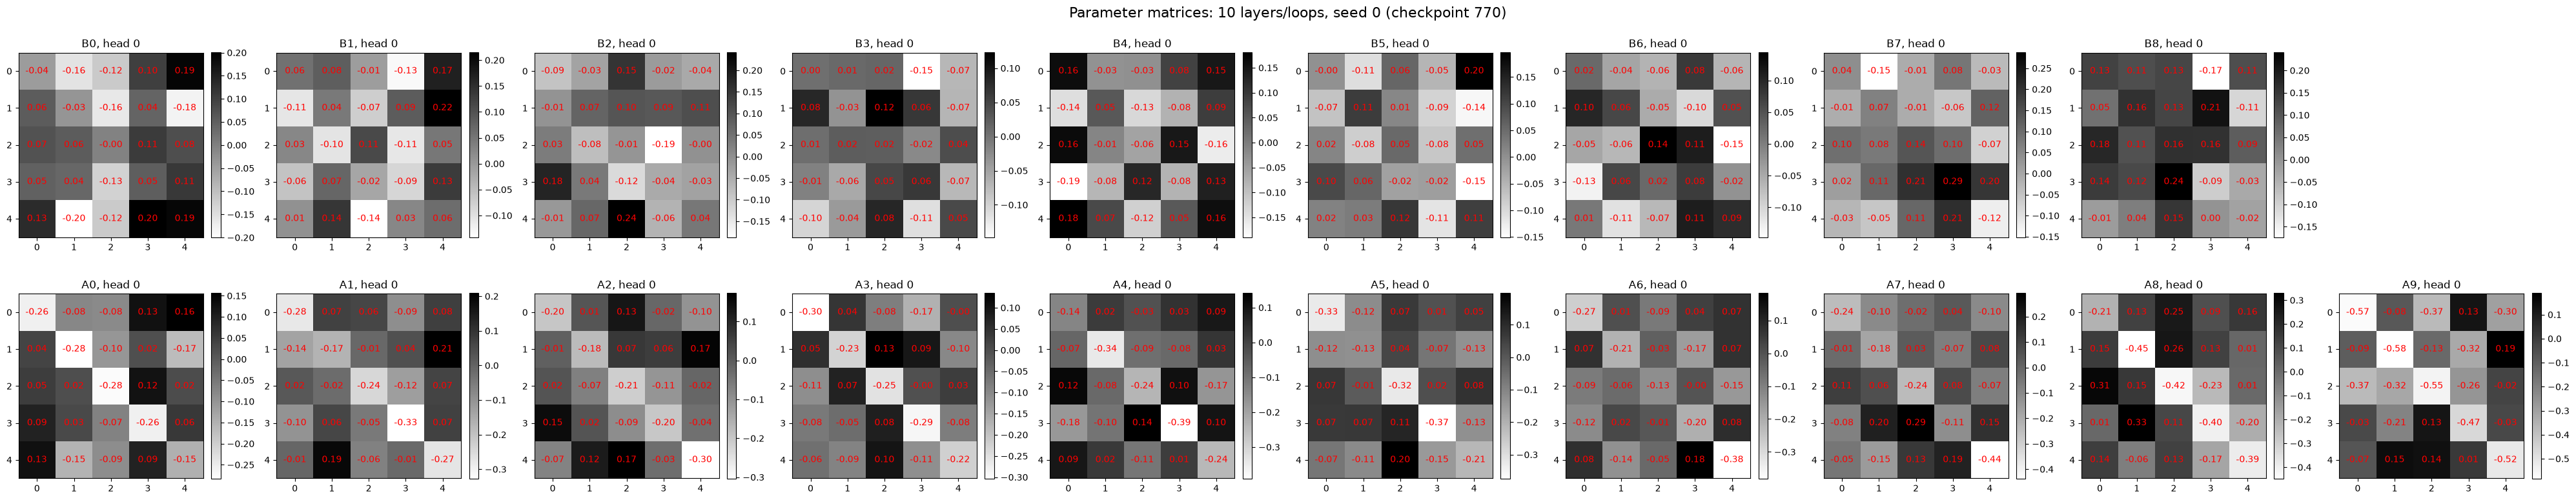

In [95]:
####################################
# display parameter matrices for each layer/loop count
# one figure per layer count, using the first available seed
####################################

plot_seed = seeds[0]

for layer_count in n_layers_loops:
    key = (plot_seed, layer_count)
    if key not in hist_dict:
        matching_keys = [k for k in hist_dict if len(k) > 1 and k[1] == layer_count]
        if not matching_keys:
            print(f'No saved run found for layer count {layer_count}; skipping.')
            continue
        key = matching_keys[0]

    history = hist_dict[key]
    snapshot_index = next(
        (idx for idx in range(len(history) - 1, -1, -1)
         if torch.isfinite(history[idx]).all()),
        None,
    )
    if snapshot_index is None:
        print(f'No finite checkpoint found for {key}; skipping.')
        continue

    snapshot = history[snapshot_index]
    layer_count = key[1]
    fig, axs = plt.subplots(
        2 * n_head, layer_count,
        figsize=(4 * layer_count, 4 * 2 * n_head),
        squeeze=False,
    )

    # B matrices exist for all but the final layer.
    for h in range(n_head):
        for l in range(layer_count - 1):
            ax = axs[h, l]
            matrix = snapshot[l, h, 0, :, :].detach().cpu()
            im = ax.imshow(matrix, cmap='gray_r')
            for i in range(matrix.shape[0]):
                for j in range(matrix.shape[1]):
                    ax.text(j, i, f'{matrix[i, j].item():.2f}',
                            ha='center', va='center', color='r')
            ax.set_title(f'B{l}, head {h}')
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        axs[h, layer_count - 1].axis('off')

    # A matrices exist for every layer.
    for h in range(n_head):
        for l in range(layer_count):
            ax = axs[n_head + h, l]
            matrix = snapshot[l, h, 1, :, :].detach().cpu()
            im = ax.imshow(matrix, cmap='gray_r')
            for i in range(matrix.shape[0]):
                for j in range(matrix.shape[1]):
                    ax.text(j, i, f'{matrix[i, j].item():.2f}',
                            ha='center', va='center', color='r')
            ax.set_title(f'A{l}, head {h}')
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    fig.suptitle(
        f'Parameter matrices: {layer_count} layers/loops, seed {key[0]} '
        f'(checkpoint {snapshot_index * hist_stride})',
        fontsize=16,
    )
    fig.tight_layout()
    fig.savefig(
        os.path.join(fig_dir, f'figure_two_parameters_L{layer_count}_seed{key[0]}.pdf'),
        dpi=600,
        bbox_inches='tight',
    )
    plt.show()

In [98]:
########################################################
# compute distance-to-identity for each layer/loop count
########################################################

def compute_dist_identity(M):
    scale = torch.diagonal(M).sum() / M.shape[0]
    ideal_identity = scale * torch.eye(M.shape[0], device=M.device, dtype=M.dtype)
    denominator = torch.linalg.norm(M, ord='fro')
    if not torch.isfinite(denominator) or denominator == 0:
        return float('nan')
    return (torch.linalg.norm(M - ideal_identity, ord='fro') / denominator).item()

# Store one distance history per (seed, layer_count). Missing checkpoints remain NaN.
dist_dict = {}
iterations = np.arange(0, max_iters, stride)

for key, history in hist_dict.items():
    layer_count = key[1]
    distances = torch.full((layer_count, 2, len(iterations)), float('nan'))

    for point_index, iteration in enumerate(iterations):
        if iteration % hist_stride != 0:
            continue
        history_index = iteration // hist_stride
        if history_index >= len(history):
            break

        snapshot = history[history_index]
        if not torch.isfinite(snapshot).all():
            continue

        for layer in range(layer_count):
            for matrix_type in range(2):
                # The experiment uses one head; average across heads if n_head is increased.
                head_distances = [
                    compute_dist_identity(snapshot[layer, head, matrix_type])
                    for head in range(n_head)
                ]
                finite_distances = [value for value in head_distances if np.isfinite(value)]
                if finite_distances:
                    distances[layer, matrix_type, point_index] = float(np.mean(finite_distances))

    dist_dict[key] = distances

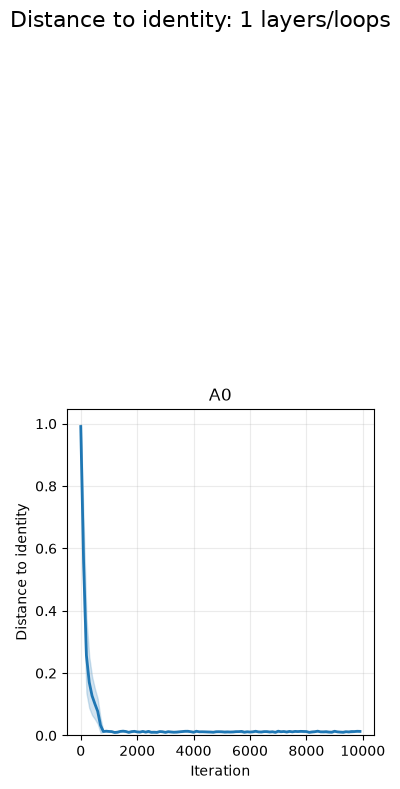

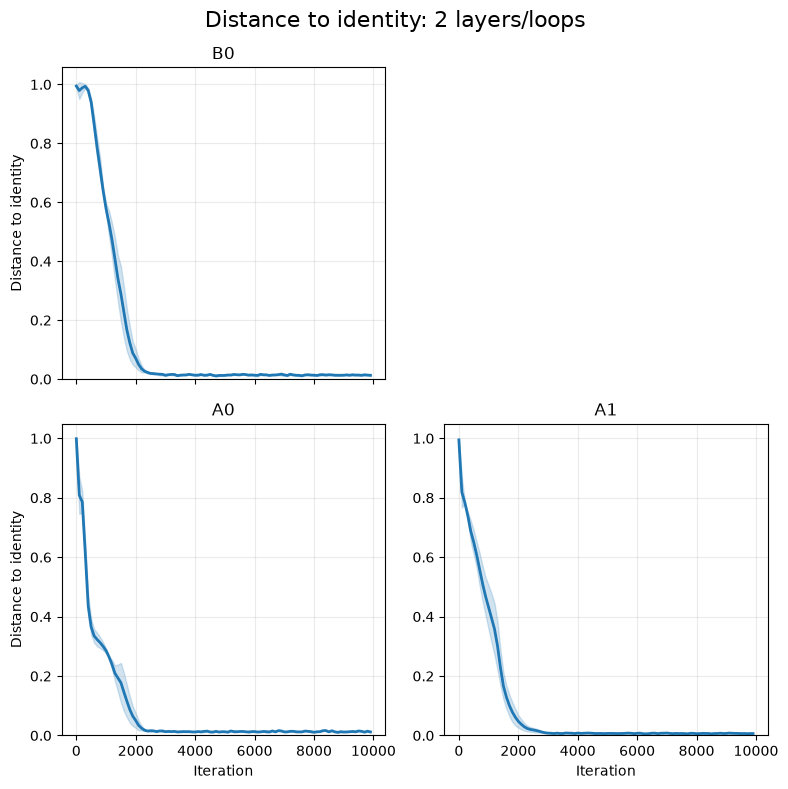

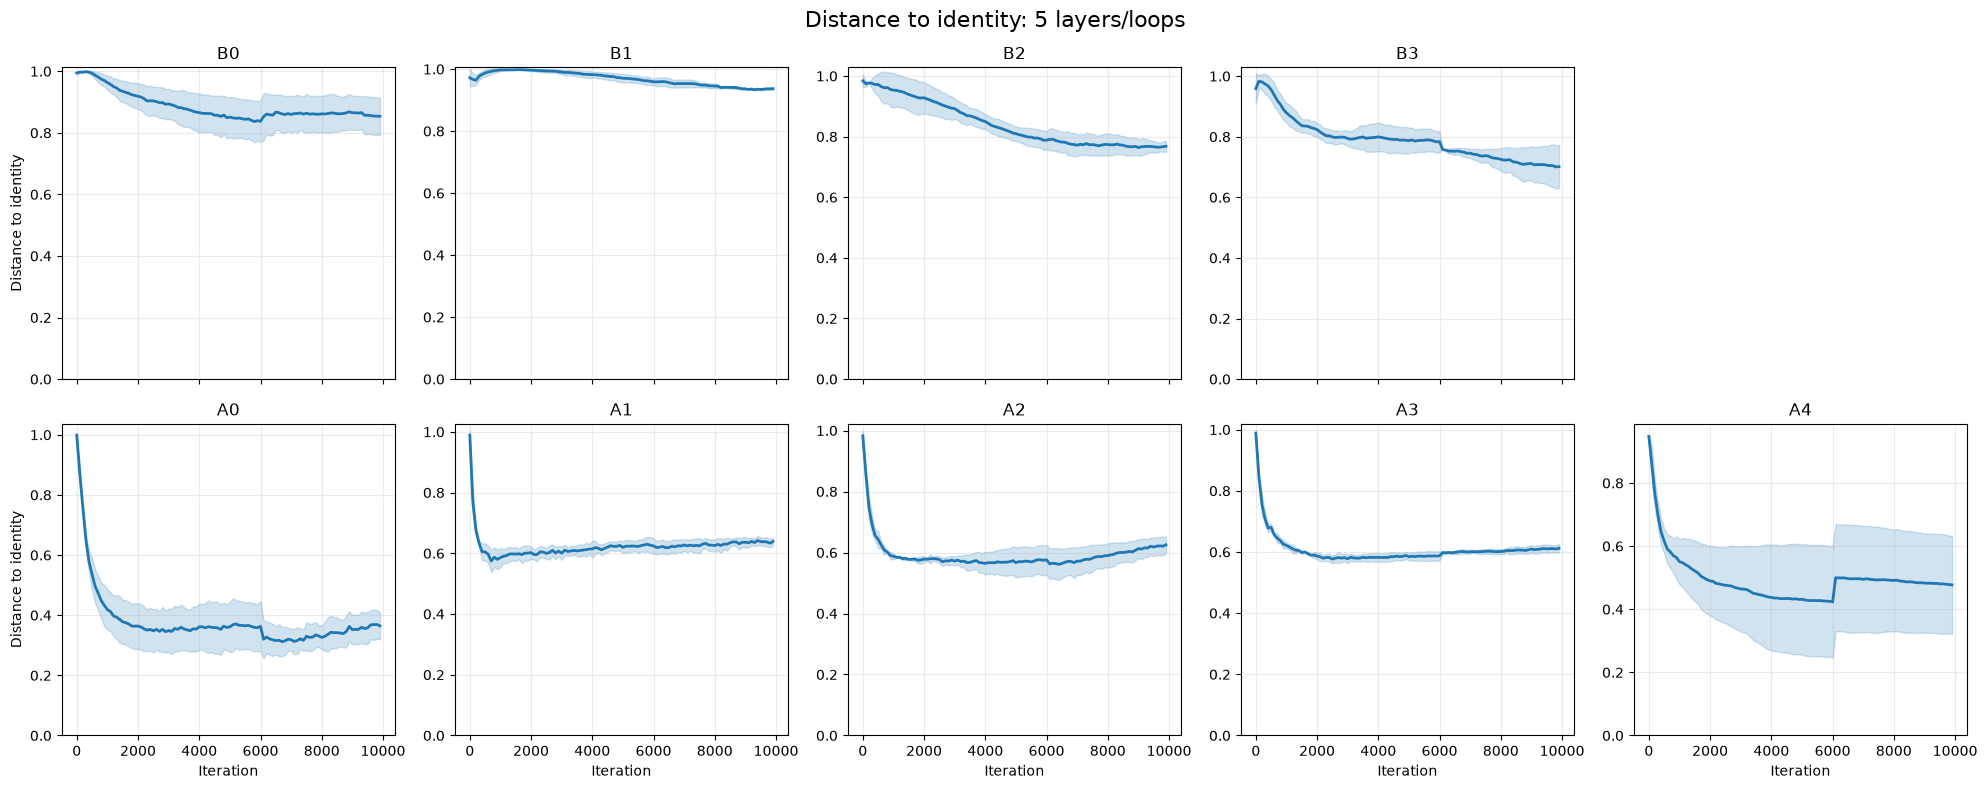

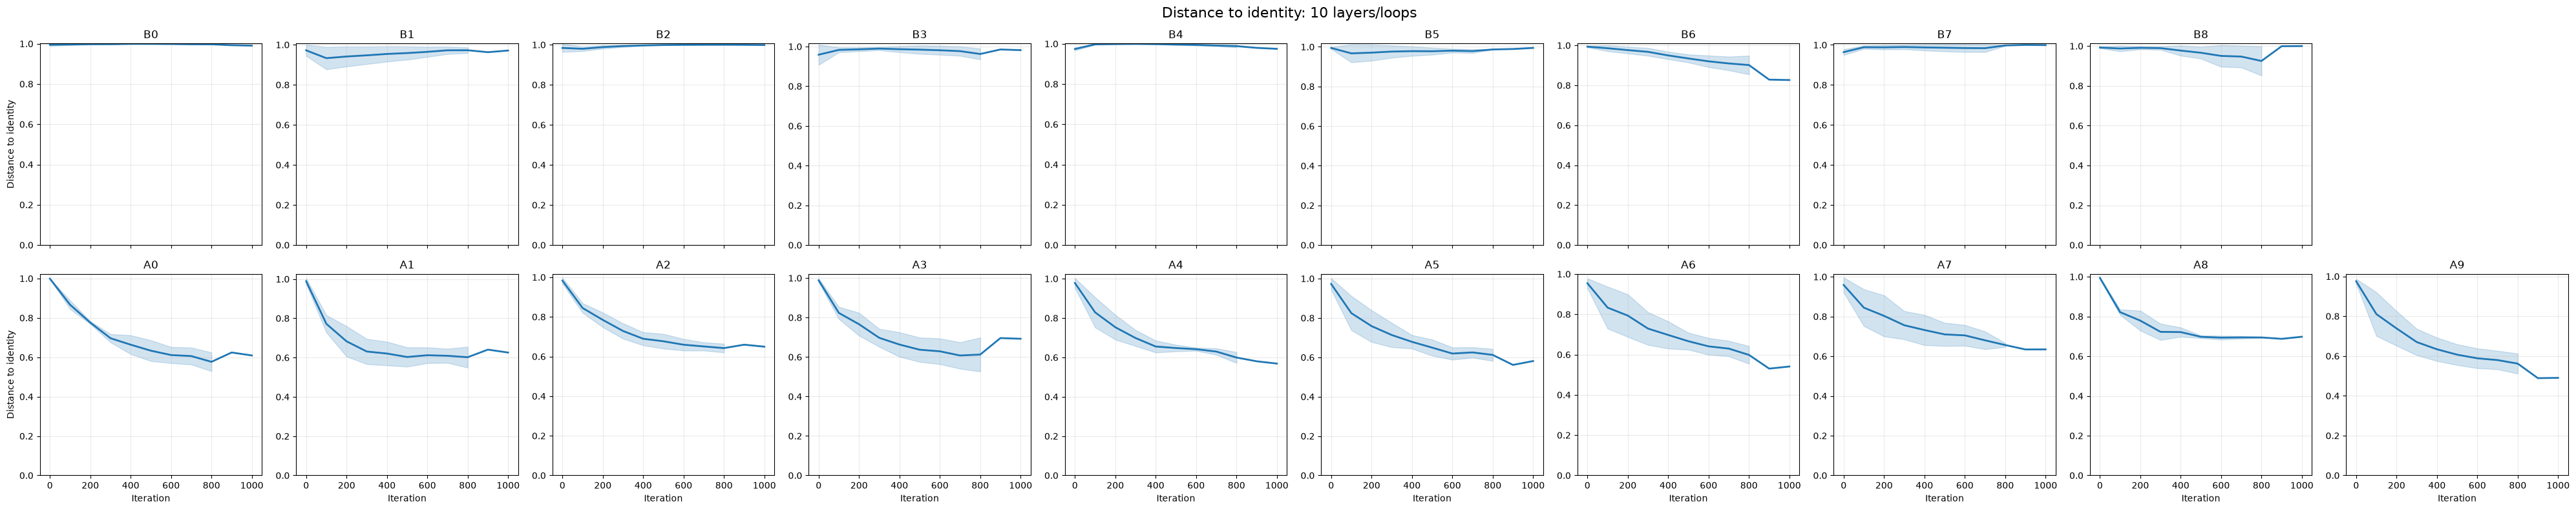

In [99]:
########################################################
# plot distance-to-identity separately for each layer/loop count
########################################################

for layer_count in n_layers_loops:
    matching_keys = [key for key in dist_dict if key[1] == layer_count]
    if not matching_keys:
        print(f'No distance histories found for {layer_count} layers/loops; skipping.')
        continue

    fig, axs = plt.subplots(
        2, layer_count,
        figsize=(4 * layer_count, 8),
        squeeze=False,
        sharex=True,
    )

    for matrix_type, matrix_name in enumerate(('B', 'A')):
        for layer in range(layer_count):
            ax = axs[matrix_type, layer]
            if matrix_type == 0 and layer == layer_count - 1:
                ax.axis('off')
                continue

            seed_curves = torch.stack([
                dist_dict[key][layer, matrix_type] for key in matching_keys
            ])
            valid = torch.isfinite(seed_curves)
            count = valid.sum(dim=0)
            values = torch.where(valid, seed_curves, torch.zeros_like(seed_curves))
            mean = values.sum(dim=0) / count.clamp_min(1)
            mean[count == 0] = float('nan')

            variance = torch.where(
                valid,
                (seed_curves - mean.unsqueeze(0)) ** 2,
                torch.zeros_like(seed_curves),
            ).sum(dim=0) / count.clamp_min(1)
            std = variance.sqrt()
            ax.plot(iterations, mean.numpy(), color='tab:blue', lw=2)
            multiple = count > 1
            lower = torch.where(multiple, mean - std, torch.nan)
            upper = torch.where(multiple, mean + std, torch.nan)
            ax.fill_between(
                iterations, lower.numpy(), upper.numpy(),
                color='tab:blue', alpha=0.2,
            )
            ax.set_title(f'{matrix_name}{layer}')
            ax.set_ylim(bottom=0)
            ax.grid(True, alpha=0.25)

    for ax in axs[-1, :]:
        if ax.axison:
            ax.set_xlabel('Iteration')
    for ax in axs[:, 0]:
        if ax.axison:
            ax.set_ylabel('Distance to identity')

    fig.suptitle(f'Distance to identity: {layer_count} layers/loops', fontsize=16)
    fig.tight_layout()
    fig.savefig(
        os.path.join(fig_dir, f'figure_two_dist_to_identity_L{layer_count}.pdf'),
        dpi=600,
        bbox_inches='tight',
    )
    plt.show()